# DLMDSAS01 - Advanced Statistics

#### - Imports -

In [2]:
from scipy.special import comb, kv, kve
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy import stats
from scipy.stats import chi2
import numpy as np
import matplotlib.pyplot as plt

## Task 1 - Basic Probabilities and Visualizations (1)

### Parameters

In [ ]:
k = 78      # ξ2
p = 0.49    # ξ3

### PMF

In [4]:
def pmf(m):
    return comb(m + k - 1, k - 1) * (p**k) * ((1 - p)**m)

### Distribution

In [5]:
m_vals = []
pmf_vals = []

m = 0
peak_passed = False

while True:
    prob = pmf(m)
    
    m_vals.append(m)
    pmf_vals.append(prob)
    
    if m > 0 and pmf_vals[-1] < pmf_vals[-2]:
        peak_passed = True
    
    if peak_passed and prob < 0.005:
        break
    
    m += 1

m_vals = np.array(m_vals)
pmf_vals = np.array(pmf_vals)

### Expectation (mean)

In [6]:
mean = k * (1 - p) / p

print(f"Expectation (mean): {mean:.4f}")

Expectation (mean): 81.1837


### Median

In [7]:
cum = np.cumsum(pmf_vals)
median = np.searchsorted(cum, 0.5)

print(f"Median: {median}")

Median: 81


### Graphic Visualization

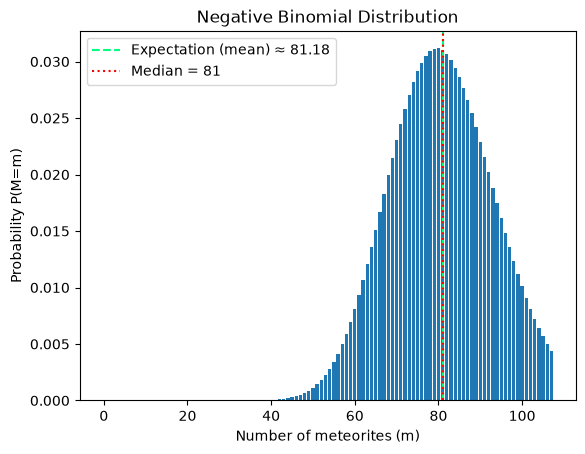

In [8]:
plt.figure()
plt.bar(m_vals, pmf_vals)

plt.axvline(mean, linestyle='--', color="springgreen", label=f"Expectation (mean) ≈ {mean:.2f}")
plt.axvline(median, linestyle=':', color="red", label=f"Median = {median}")

plt.xlabel("Number of meteorites (m)")
plt.ylabel("Probability P(M=m)")
plt.title("Negative Binomial Distribution")

plt.legend()

plt.savefig("Graphics/graphic_task1.pdf", format='pdf', dpi=300, bbox_inches='tight')

plt.show()

## Task 2 - Basic Probabilities and Visualizations (2)

### Parameters

In [ ]:
a = 2/9    # ξ5
b = 4      # ξ6
c = 7/9    # ξ7
d = 9      # ξ8

### Survival function

In [47]:
def s(y):
    return (a * np.exp(-b * y**2) + c * np.exp(-d * y**8))

### Computation of Probability

In [48]:
probability = s(2) - s(4)
print(f"{probability:.10f}")

0.0000000250


### PDF (Probability Density Function)

In [49]:
def f(y):
    return (2 * a * b * y * np.exp(-b * y**2) + 8 * c * d * y**7 * np.exp(-d * y**8))

### CDF (Cumulative Density Function)

In [50]:
def cdf_task2(y):
    return (1 - s(y))

###  Mean, Variance, and Quartiles

In [51]:
mean, _ = quad(lambda y: y * f(y), 0, np.inf)

second_moment, _ = quad(lambda y: y**2 * f(y), 0, np.inf)
variance = second_moment - mean**2

q25 = brentq(lambda y: cdf_task2(y) - 0.25, 0, 2)
q50 = brentq(lambda y: cdf_task2(y) - 0.5, 0, 2)
q75 = brentq(lambda y: cdf_task2(y) - 0.75, 0, 2)

print(f"Mean: {mean:.2f}")
print(f"Variance: {variance:.2f}")
print(f"First Quartile (25th percentile): {q25:.2f}")
print(f"Second Quartile (50th percentile / Median): {q50:.2f}")
print(f"Third Quartile (75th percentile): {q75:.2f}")

Mean: 0.66
Variance: 0.03
First Quartile (25th percentile): 0.58
Second Quartile (50th percentile / Median): 0.70
Third Quartile (75th percentile): 0.78


### PDF Graph

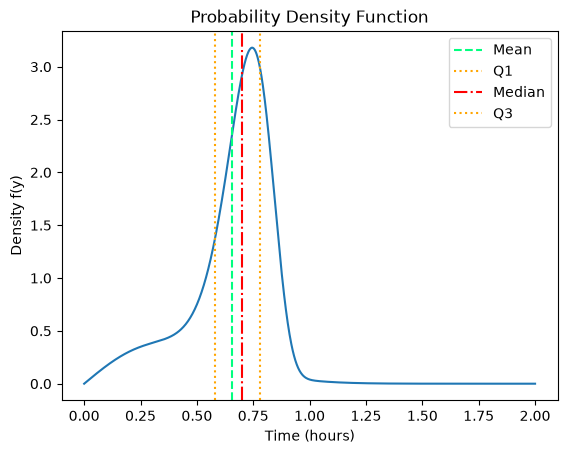

In [52]:
y = np.linspace(0, 2, 1000)

plt.plot(y, f(y))

plt.axvline(mean, linestyle='--', color="springgreen", label='Mean')
plt.axvline(q25, linestyle=':', color="orange", label='Q1')
plt.axvline(q50, linestyle='-.', color="red", label='Median')
plt.axvline(q75, linestyle=':', color="orange", label='Q3')

plt.legend()
plt.xlabel("Time (hours)")
plt.ylabel("Density f(y)")
plt.title("Probability Density Function")

plt.savefig("Graphics/pdf_task2.pdf", format='pdf', dpi=300, bbox_inches='tight')

plt.show()

### Histogram

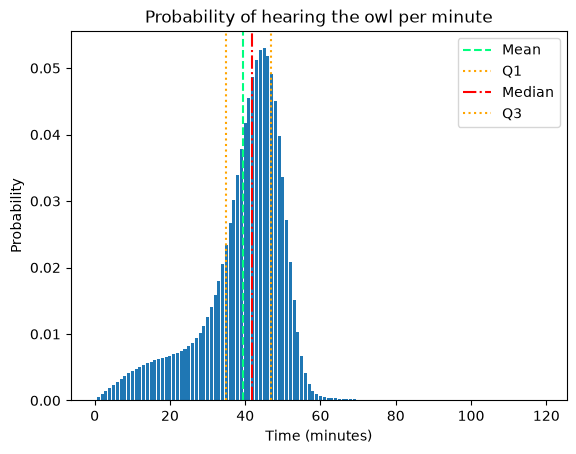

In [53]:
minutes = np.arange(0, 120)
y_minutes = minutes / 60

delta = 1/60
probs = f(y_minutes) * delta

plt.bar(minutes, probs)

plt.axvline(mean*60, linestyle='--', color="springgreen",label='Mean')
plt.axvline(q25*60, linestyle=':', color="orange", label='Q1')
plt.axvline(q50*60, linestyle='-.', color="red", label='Median')
plt.axvline(q75*60, linestyle=':', color="orange", label='Q3')

plt.legend()
plt.xlabel("Time (minutes)")
plt.ylabel("Probability")
plt.title("Probability of hearing the owl per minute")

plt.savefig("Graphics/histogram_task2.pdf", format='pdf', dpi=300, bbox_inches='tight')

plt.show()

## Task 3 - Transformed Random Variables

### Parameters

In [ ]:
bandwidth_totals = [37, 52, 64, 18, 0]  # ξ10

### Maximum Likelihood Estimator

In [ ]:
theta_hat = np.mean(bandwidth_totals) / 2

### Expectation of T

In [42]:
E_T = 2 * theta_hat

### Results

In [45]:
print("MLE theta:", theta_hat)
print("Expected T:", E_T)

MLE theta: 17.1
Expected T: 34.2


## Task 4 - Hypothesis Test

### Parameters

In [ ]:
samples = [928, 938, 950, 954, 941, 936, 1008, 937, 939, 966]   # ξ14
n = len(samples)
sigma0 = 35.2       # ξ12
alpha = 0.05

### Mean

In [22]:
mean = np.mean(samples)
print(f"Mean: {mean}")

Mean: 949.7


### Variance

In [23]:
s2 = np.var(samples, ddof=1)
print(f"Variance: {s2:.2f}")

Variance: 536.68


### Chi-square test statistic

In [24]:
chi_square = (n-1)*s2/(sigma0**2)
print(f"Chi-square: {chi_square:.3f}")

Chi-square: 3.898


#### Critical Value for Left-tailed test

In [25]:
critical = chi2.ppf(alpha, df=n-1)
print(f"Critical Value for Left-tailed test: {critical:.3f}")

Critical Value for Left-tailed test: 3.325


#### p-value

In [28]:
p_value = chi2.cdf(chi_square, df=n-1)
print(f"p-value: {p_value:.3f}")

p-value: 0.082


### Type II error probability

In [26]:
# assume the new system has a standard deviation of 30 g

sigma1 = 30

beta = 1 - chi2.cdf(
    critical * (sigma0**2 / sigma1**2),
    df=n-1
)

print(f"Type II error probability (beta): {beta:.3f}")

Type II error probability (beta): 0.869


### Power of the test

In [27]:
power = 1 - beta

print(f"Power (1 - beta): {power:.3f}")

Power (1 - beta): 0.131


## Task 5: Regularized Regression

### Parameters

In [ ]:
data = [(-6, 6038422291.73), (-7, 37102435277.92), (6, 7987712684.26),
(-14, 155345310475368.06), (-12, 24623459385110.95), (10,
3248796791320.71), (4, 68668227.69), (-16, 833719741222972.5),
(-17, 1641343452564754), (14, 187943996770917.84), (-19,
6375474630693752), (-8, 196293759232.3), (1, 38.08), (15,
434811484112158.25), (17, 1797962615235692.2), (7,
50605917639.08), (-13, 64849485988643.69), (2, 27217.5), (9,
937162591525.51), (-1, -4.06), (16, 901265743566097.1), (3,
2564389.54), (20, 12489064946603642), (-15, 366972436510100.4),
(-18, 3361052474760982), (19, 7039505527892020)]    # ξ15

x_data, y_data = zip(*data)

x = np.array(x_data)
y = np.array(y_data)

### Design matrix

In [30]:
X = np.column_stack([x**i for i in range(13)])

alpha_ols, _, _, _ = np.linalg.lstsq(
    X, y, rcond=None
)

### OLS

In [31]:
alpha_ols, _, _, _ = np.linalg.lstsq(X, y, rcond=None)

y_pred_ols = X @ alpha_ols

sse_ols = np.sum((y - y_pred_ols)**2)

print("\nOLS coefficients:")
print(alpha_ols)

print("\nOLS SSE:")
print(sse_ols)


OLS coefficients:
[-8.50125790e+06 -4.72841367e+09  1.06581933e+09 -1.26668539e+11
 -2.03969685e+10  3.12731029e+09  4.45124983e+08 -2.34259445e+07
 -3.19857312e+06  6.95610649e+04  9.40102155e+03 -6.91731995e+01
 -6.73126984e+00]

OLS SSE:
8.168961974523782e+27


### Ridge

In [32]:
lambdas = [0.0, 1.0, 1e3, 1e5, 1e7, 1e9, 1e11, 1e13, 1e15, 1e17, 1e19, 1e21, 1e23]

P = np.diag([0] + [1] * 12)

for lambda_ in lambdas:

    X_ridge = np.vstack([
        X,
        np.sqrt(lambda_) * P
    ])

    y_ridge = np.concatenate([
        y,
        np.zeros(13)
    ])

    alpha_ridge, _, _, _ = np.linalg.lstsq(
        X_ridge, y_ridge, rcond=None
    )

    y_pred_ridge = X @ alpha_ridge
    sse_ridge = np.sum((y - y_pred_ridge)**2)
    coefficient_norm = np.linalg.norm(alpha_ridge[1:])

    print(
        f"lambda={lambda_:>8g} | "
        f"SSE={sse_ridge:.3e} | "
        f"||alpha_1:12||={coefficient_norm:.3e}"
    )

lambda=       0 | SSE=8.169e+27 | ||alpha_1:12||=1.284e+11
lambda=       1 | SSE=8.169e+27 | ||alpha_1:12||=1.284e+11
lambda=    1000 | SSE=8.169e+27 | ||alpha_1:12||=1.270e+11
lambda=  100000 | SSE=8.551e+27 | ||alpha_1:12||=6.311e+10
lambda=   1e+07 | SSE=1.075e+28 | ||alpha_1:12||=9.791e+09
lambda=   1e+09 | SSE=1.340e+28 | ||alpha_1:12||=5.299e+08
lambda=   1e+11 | SSE=1.476e+28 | ||alpha_1:12||=9.532e+07
lambda=   1e+13 | SSE=2.059e+28 | ||alpha_1:12||=5.840e+06
lambda=   1e+15 | SSE=2.179e+28 | ||alpha_1:12||=9.631e+05
lambda=   1e+17 | SSE=2.536e+28 | ||alpha_1:12||=1.446e+05
lambda=   1e+19 | SSE=3.774e+28 | ||alpha_1:12||=7.784e+03
lambda=   1e+21 | SSE=3.922e+28 | ||alpha_1:12||=1.013e+03
lambda=   1e+23 | SSE=4.444e+28 | ||alpha_1:12||=1.302e+02


In [33]:
lambda_ = 100000

P = np.diag([0] + [1] * 12)

X_ridge = np.vstack([
    X,
    np.sqrt(lambda_) * P
])

y_ridge = np.concatenate([
    y,
    np.zeros(13)
])

alpha_ridge, _, _, _ = np.linalg.lstsq(
    X_ridge, y_ridge, rcond=None
)

y_pred_ridge = X @ alpha_ridge

sse_ridge = np.sum((y - y_pred_ridge)**2)

print("\nRidge coefficients:")
print(alpha_ridge)

print("\nRisdge SSE:")
print(sse_ridge)


Ridge coefficients:
[-1.03271003e+07 -1.24371234e+09  9.12817864e+09 -5.86153138e+10
 -2.14248364e+10  1.79092678e+09  4.62436615e+08 -1.44790982e+07
 -3.32012036e+06  4.46660755e+04  9.77862853e+03 -4.44729659e+01
 -7.15438628e+00]

Risdge SSE:
8.550727351809331e+27


In [34]:
penalty_ols = np.sum(alpha_ols[1:]**2)
penalty_ridge = np.sum(alpha_ridge[1:]**2)

print("OLS penalty:", penalty_ols)
print("Ridge penalty:", penalty_ridge)

OLS penalty: 1.6494427820214792e+22
Ridge penalty: 3.9830705747518565e+21


### Plot

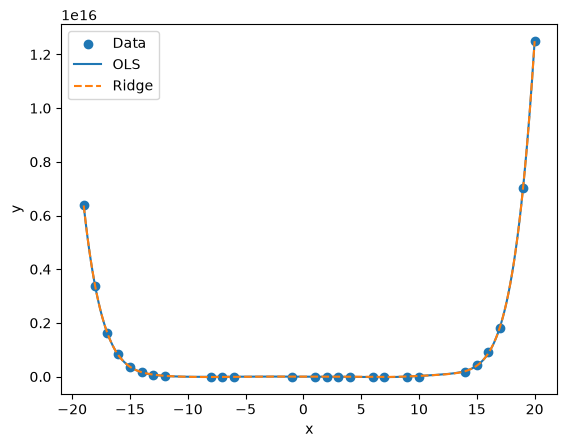

In [35]:
x_plot = np.linspace(min(x), max(x), 500)

X_plot = np.column_stack([
    x_plot**i for i in range(13)
])

y_plot_ols = X_plot @ alpha_ols
y_plot_ridge = X_plot @ alpha_ridge

plt.scatter(x, y, label="Data")
plt.plot(x_plot, y_plot_ols, label="OLS")
plt.plot(x_plot, y_plot_ridge, label="Ridge", linestyle='dashed')

plt.xlabel("x")
plt.ylabel("y")
plt.legend()

plt.savefig("Graphics/plot_task5.pdf", format='pdf', dpi=300, bbox_inches='tight')

plt.show()

## Task 6

### Parameters

In [ ]:
xi17 = 56.0     # ξ17
xi18 = 67.0     # ξ18
xi19 = 82.57    # ξ19

n = 10
alpha = 3

### a) Posterior Distribution of $\theta$

In [37]:
# Posterior parameters in shape-rate form

shape = xi17 + 3 * n
rate = n * xi19 + 1 / xi18

In [ ]:
# Convert rate to scale

scale = 1 / rate

In [39]:
print(f"shape = {shape}")
print(f"rate = {rate:.8f}")
print(f"scale = {scale:.8f}")

shape = 86.0
rate = 825.71492537
scale = 0.00121107


### b) Bayes point estimate of $\theta$ associated with the square-error loss function

In [40]:
posterior_mean = shape / rate

print(f"Bayes estimate (squared-error loss): {posterior_mean:.8f}")

Bayes estimate (squared-error loss): 0.10415217


### c) Bayes point estimate of $\theta$ using the mode of the posterior distribution

In [41]:
posterior_mode = (shape - 1) / rate

print(posterior_mode)

0.10294109672486439
